# CNN, LSTM, and GRU with tinygrad / OpenCL

Compare binary fall/non-fall classifiers on the three current `amplitude_sequence_v2` exports. Every model receives all **96 Hz** samples: 192, 384, or 576 steps for 2, 4, or 6 seconds. Receiver views are synchronized and fused as feature channels. Inputs preserve full time resolution; recurrent training propagates gradients over the entire sequence.

The split holds out attempts, stratified by dataset and activity, with approximately 60% training, 20% validation, and 20% test groups. All overlapping windows and durations from an attempt stay together. The reported results do not establish participant- or session-independent performance. Fall targets follow action cues, not impact annotations; centered Hampel filtering uses future samples.

Install Python dependencies with `uv sync --inexact --extra analysis --extra tinygrad-legacy --extra notebook`. Select the project `.venv` kernel. On this Fedora/AMD machine, install `mesa-libOpenCL.x86_64` and enable `RUSTICL_ENABLE=radeonsi`. The notebook requires OpenCL and reports runtime failures without switching backends. Each fresh run creates a separate timestamped results directory.

GPU jobs run in separate workers capped at 4 GB RAM, without swap, and four CPU cores. Training uses 32-window effective batches and recurrent microbatches with 32-step recomputation; state gradients cross every boundary. Evaluation replays bounded forward schedules and masks extra batch slots. This preserves full-resolution inputs and full BPTT.

Saved outputs may belong to the earlier v1 run; execute the notebook to regenerate them from v2. The v2 migration and guarded `akmal` pilot are documented in `docs/reports/sequence-segment-store-2026-11-11.md`. The default run profiles three epochs on four windows from each existing split/duration/dataset/activity/target stratum before estimating full-data runtime. Pilot statistics and checkpoints stay under `profile/`. Set `RUN_FULL_TRAINING=True` to train the complete datasets after inspecting these measurements. Pilot accuracy does not predict full-data accuracy.

## Setup and experiment settings

Run top to bottom from a fresh kernel. The three model configurations below can be edited independently. A seed fixes initialization and batch order; identical results across driver versions are not guaranteed.

In [4]:
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict
from time import perf_counter
import hashlib
import json
import os
import sys

os.environ["DEV"] = "CL"
os.environ.setdefault("RUSTICL_ENABLE", "radeonsi")

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "src/fall_detection").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import polars as pl
from IPython.display import display
from fall_detection.analysis.sequence_training_data import (
    DURATIONS, LABELS, SegmentStore, SequenceDataset,
    load_sequence_index, split_sequence_attempts, fit_normalizer,
)
from fall_detection.analysis.tinygrad_training import (
    TrainingConfig, comparison_table, plot_results, write_json,
)

from fall_detection.analysis.sequence_training_profile import prepare_profile, profile_table, refresh_projections

RUN_FULL_TRAINING = False
PROFILE_WINDOWS_PER_STRATUM = 4
WINDOW_DURATIONS = DURATIONS
SPLIT_SEED = 42
DATA_ROOT = PROJECT_ROOT / "data/processed/amplitude_sequence_v2"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RESULT_DIR = PROJECT_ROOT / "data/processed/tinygrad_binary_v1" / RUN_ID
RESULT_DIR.mkdir(parents=True, exist_ok=False)
print("Results:", RESULT_DIR)
print("Python:", sys.executable)
from fall_detection.analysis.sequence_training_worker import run_worker


Results: /home/khaelano/Projects/radio-fall-detection/data/processed/tinygrad_binary_v1/20261111T104436078493Z
Python: /home/khaelano/Projects/radio-fall-detection/.venv/bin/python


## Index, fixed attempt split, and coverage

Read existing export indexes and manifests. Raw recordings remain unchanged; each window indexes a memory-mapped segment signal. Window counts differ from independent attempt counts. No coverage threshold or class resampling is applied.

In [5]:
preparation_started = perf_counter()
index, sources = load_sequence_index(DATA_ROOT)
index = split_sequence_attempts(index, SPLIT_SEED)
index.write_parquet(RESULT_DIR / "window_split.parquet")
provenance = {
    "sources": sources,
    "split_seed": SPLIT_SEED,
    "split_unit": "session + attempt, shared across durations",
    "split_sha256": hashlib.sha256((RESULT_DIR / "window_split.parquet").read_bytes()).hexdigest(),
    "code_sha256": {
        name: hashlib.sha256((PROJECT_ROOT / "src/fall_detection/analysis" / name).read_bytes()).hexdigest()
        for name in ("sequence_training_data.py", "tinygrad_training.py", "sequence_training_worker.py", "sequence_training_profile.py")
    },
}
write_json(RESULT_DIR / "manifest.json", {
    "provenance": provenance, "labels": LABELS,
    "limitation": "Held-out attempts; cue-centered window labels; offline centered filtering; no participant/session holdout.",
})
display(index.group_by("dataset", "split").agg(pl.col("group").n_unique().alias("attempts")).sort("dataset", "split"))
display(index.group_by("duration", "split", "target").len().sort("duration", "split", "target"))
coverage = index.group_by("dataset", "duration", "split").agg(
    pl.len().alias("windows"), pl.col("coverage").min().alias("minimum"),
    pl.col("coverage").quantile(0.1).alias("p10"), pl.col("coverage").median().alias("median"),
    pl.col("coverage").mean().alias("mean"),
).sort("dataset", "duration", "split")
coverage.write_csv(RESULT_DIR / "coverage.csv")
display(coverage)
metadata_preparation_seconds = perf_counter() - preparation_started

dataset,split,attempts
str,str,u32
"""akmal""","""test""",46
"""akmal""","""train""",138
"""akmal""","""validation""",47
"""continuous_non_fall""","""test""",2
"""continuous_non_fall""","""train""",8
"""continuous_non_fall""","""validation""",2
"""khaelano""","""test""",47
"""khaelano""","""train""",139
"""khaelano""","""validation""",46


duration,split,target,len
i64,str,i64,u32
2,"""test""",0,1386
2,"""test""",1,139
2,"""train""",0,4751
2,"""train""",1,382
2,"""validation""",0,1397
…,…,…,…
6,"""test""",1,54
6,"""train""",0,1399
6,"""train""",1,159


dataset,duration,split,windows,minimum,p10,median,mean
str,i64,str,u32,f64,f64,f64,f64
"""akmal""",2,"""test""",450,0.175446,0.710805,0.806813,0.775836
"""akmal""",2,"""train""",1364,0.156207,0.677487,0.806803,0.765005
"""akmal""",2,"""validation""",473,0.309938,0.699766,0.808131,0.776673
"""akmal""",4,"""test""",208,0.435427,0.728757,0.802394,0.778019
"""akmal""",4,"""train""",627,0.245267,0.691061,0.799814,0.767012
…,…,…,…,…,…,…,…
"""khaelano""",4,"""train""",631,0.481346,0.790854,0.808759,0.801204
"""khaelano""",4,"""validation""",210,0.644839,0.78044,0.80879,0.800399
"""khaelano""",6,"""test""",135,0.637806,0.762461,0.808564,0.796579


## Verify OpenCL in a bounded worker

All GPU work runs in a separate systemd scope with a hard 4 GB memory cap, no swap, a four-core CPU quota, and a runtime limit. If containment is unavailable or fails, the notebook stops. There is no direct-kernel fallback.

In [6]:
runtime = run_worker(RESULT_DIR, "probe")
write_json(RESULT_DIR / "runtime.json", runtime)
display(runtime)

=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===


{'device': 'CL',
 'device_name': 'AMD Radeon Graphics (radeonsi, renoir, ACO, DRM 3.64, 7.2.15-200.fc44.x86_64)',
 'driver_version': '26.2.6',
 'tinygrad': '0.14.0',
 'numpy': '2.5.2',
 'polars': '2.1.0',
 'scikit_learn': '1.9.1',
 'rusticl_enable': 'radeonsi',
 'memory_limit_bytes': 4000000000,
 'cpu_quota_percent': 400}

## Stratified subset preparation

Select four windows per existing split, duration, dataset, activity, and target stratum with seed 42. Attempts retain their original split. Fit pilot normalizers exclusively on the selected training windows; held-out signals never enter these statistics. Inputs retain all 96 Hz steps and all receiver/subcarrier features. The bounded cache and one ready batch avoid materializing a full dataset.

In [7]:
pilot_selection = prepare_profile(RESULT_DIR, PROFILE_WINDOWS_PER_STRATUM, SPLIT_SEED)
display(pl.DataFrame(pilot_selection["subset_counts"]))

# Full-data normalization is deferred until a complete-data model is requested.
preparation_seconds = {}
def run_duration(kind, duration, config):
    if duration not in preparation_seconds:
        started = perf_counter()
        store = SegmentStore()
        normalizer = fit_normalizer(index.filter(pl.col("duration") == duration), store)
        normalizer.save(RESULT_DIR / f"normalizer-{duration}s.npz")
        store.clear()
        preparation_seconds[duration] = metadata_preparation_seconds + perf_counter() - started
        write_json(RESULT_DIR / "preparation_seconds.json", preparation_seconds)
    return run_worker(RESULT_DIR, "train", kind=kind, duration=duration, config=asdict(config))


duration,split,len
i64,str,i64
2,"""test""",76
2,"""train""",76
2,"""validation""",76
4,"""test""",76
4,"""train""",76
4,"""validation""",76
6,"""test""",76
6,"""train""",76
6,"""validation""",75


## Small-scale training and runtime projection

Run the real training, validation, checkpoint restore, test evaluation, and synchronized inference path for all nine model/duration combinations. Three epochs separate schedule construction from repeat execution; pilot batch-one inference uses eight test windows. Measure a full-data CPU loader pass separately, without model training, because scattered subsets can have different page-cache behavior from complete passes. Combine repeat-batch compute with the measured loading term; report ideal overlap and serial execution bounds. These are sensitivity bounds, not confidence intervals. Dataset size cannot establish a stopping epoch or predict accuracy/F1. Disk-cache behavior, thermal state, and final-batch shapes can change full-run rates.

In [8]:
profile_results = []
PROFILE_CONFIG = TrainingConfig(batch_size=32, micro_batch_size=32, recurrent_chunk_steps=32)
for duration in WINDOW_DURATIONS:
    for kind in ("cnn", "lstm", "gru"):
        profile_results.append(run_worker(
            RESULT_DIR, "profile", kind=kind, duration=duration,
            config=asdict(PROFILE_CONFIG), timeout_seconds=900,
        ))
    # One read-only CPU pass measures full-data loading; no full-data training.
    run_worker(RESULT_DIR, "loading", duration=duration, timeout_seconds=600)
    profile_results = refresh_projections(RESULT_DIR)
    projection = profile_table(profile_results)
    display(projection)
print("Projected 30-epoch training total (excluding preparation and final evaluation):",
      f'{projection["full_30_epochs_minutes"].sum() / 60:.2f} hours')


=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===
CNN 2s epoch 1/3: loss=1.0004 val F1=0.4737 (8.7s)
CNN 2s epoch 2/3: loss=0.7847 val F1=0.6538 (2.1s)
CNN 2s epoch 3/3: loss=0.7466 val F1=0.4737 (1.9s)
=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===
LSTM 2s epoch 1/3: loss=0.9636 val F1=0.4742 (26.0s)
LSTM 2s epoch 2/3: loss=0.9623 val F1=0.4848 (2.7s)
LSTM 2s epoch 3/3: loss=0.9609 val F1=0.4800 (2.8s)
=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org

model,duration,pilot_train_windows,pilot_training_seconds,full_epoch_minutes,full_30_epochs_minutes,projection_basis,worker_peak_GB
str,i64,i64,f64,f64,f64,str,f64
"""cnn""",2,76,12.654325,1.134895,34.158268,"""measured full loading""",1.232552
"""gru""",2,76,29.722779,1.884113,56.898112,"""measured full loading""",1.107902
"""lstm""",2,76,31.499931,2.093509,63.192582,"""measured full loading""",1.040081


=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===
CNN 4s epoch 1/3: loss=2.1193 val F1=0.0000 (11.8s)
CNN 4s epoch 2/3: loss=1.0968 val F1=0.4848 (4.9s)
CNN 4s epoch 3/3: loss=0.9529 val F1=0.4800 (4.8s)
=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===
LSTM 4s epoch 1/3: loss=0.9645 val F1=0.0000 (28.4s)
LSTM 4s epoch 2/3: loss=0.9628 val F1=0.3721 (5.4s)
LSTM 4s epoch 3/3: loss=0.9617 val F1=0.3824 (5.3s)
=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.or

model,duration,pilot_train_windows,pilot_training_seconds,full_epoch_minutes,full_30_epochs_minutes,projection_basis,worker_peak_GB
str,i64,i64,f64,f64,f64,str,f64
"""cnn""",2,76,12.654325,1.134895,34.158268,"""measured full loading""",1.232552
"""gru""",2,76,29.722779,1.884113,56.898112,"""measured full loading""",1.107902
"""lstm""",2,76,31.499931,2.093509,63.192582,"""measured full loading""",1.040081
"""cnn""",4,76,21.518519,1.15844,34.869544,"""measured full loading""",1.193771
"""gru""",4,76,36.52316,1.742298,52.644591,"""measured full loading""",1.35689
"""lstm""",4,76,39.078301,1.904828,57.528952,"""measured full loading""",1.349591


=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===
CNN 6s epoch 1/3: loss=1.8154 val F1=0.0000 (14.7s)
CNN 6s epoch 2/3: loss=0.9481 val F1=0.5600 (8.4s)
CNN 6s epoch 3/3: loss=0.9130 val F1=0.1714 (8.5s)
=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===
LSTM 6s epoch 1/3: loss=0.9595 val F1=0.0000 (33.7s)
LSTM 6s epoch 2/3: loss=0.9582 val F1=0.5161 (9.5s)
LSTM 6s epoch 3/3: loss=0.9572 val F1=0.4848 (9.4s)
=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.or

model,duration,pilot_train_windows,pilot_training_seconds,full_epoch_minutes,full_30_epochs_minutes,projection_basis,worker_peak_GB
str,i64,i64,f64,f64,f64,str,f64
"""cnn""",2,76,12.654325,1.134895,34.158268,"""measured full loading""",1.232552
"""gru""",2,76,29.722779,1.884113,56.898112,"""measured full loading""",1.107902
"""lstm""",2,76,31.499931,2.093509,63.192582,"""measured full loading""",1.040081
"""cnn""",4,76,21.518519,1.15844,34.869544,"""measured full loading""",1.193771
"""gru""",4,76,36.52316,1.742298,52.644591,"""measured full loading""",1.35689
"""lstm""",4,76,39.078301,1.904828,57.528952,"""measured full loading""",1.349591
"""cnn""",6,76,31.552349,1.124585,33.841773,"""measured full loading""",1.850089
"""gru""",6,76,48.036595,1.844505,55.698265,"""measured full loading""",1.616142
"""lstm""",6,76,52.546598,1.903197,57.501139,"""measured full loading""",1.630351


Projected 30-epoch training total (excluding preparation and final evaluation): 7.44 hours


## CNN

Two same-padding temporal convolutions (64 channels; kernels 5 and 3), ReLU, temporal mean, and a binary linear head.

Adam trains with training-only positive-class weighting and global gradient clipping. The earliest highest validation fall F1 selects the checkpoint; patience is five epochs. Test windows do not select checkpoints or thresholds.

In [9]:
CNN_CONFIG = TrainingConfig(
    seed=42, epochs=30, batch_size=32, learning_rate=0.001,
    patience=5, hidden_size=64, clip_norm=1.0,
)
display(asdict(CNN_CONFIG))

{'seed': 42,
 'epochs': 30,
 'batch_size': 32,
 'learning_rate': 0.001,
 'patience': 5,
 'hidden_size': 64,
 'clip_norm': 1.0,
 'recurrent_chunk_steps': 32,
 'micro_batch_size': 32,
 'inference_windows': 100}

In [10]:
cnn_results = []
if RUN_FULL_TRAINING:
    for duration in WINDOW_DURATIONS:
        cnn_results.append(run_duration("cnn", duration, CNN_CONFIG))
        display(comparison_table(cnn_results))
else:
    print("Full-data training disabled; see the measured subset profile above.")

Full-data training disabled; see the measured subset profile above.


## LSTM

One 64-unit LSTM layer over every time step; the final hidden state feeds a binary linear head.

Adam trains with training-only positive-class weighting and global gradient clipping. The earliest highest validation fall F1 selects the checkpoint; patience is five epochs. Test windows do not select checkpoints or thresholds.

For 2-second full runs, 64-step chunks improved repeat epochs on the local 304-window pilot but increased setup time. Set `LSTM_2S_CHUNK_STEPS = 32` to use the original configuration. Other durations and GRU retain 32-step chunks.

In [11]:
from dataclasses import replace

LSTM_2S_CHUNK_STEPS = 64  # Set to 32 for the original, shorter-setup configuration.
LSTM_CONFIG = TrainingConfig(
    seed=42, epochs=30, batch_size=32, learning_rate=0.001,
    patience=5, hidden_size=64, clip_norm=1.0,
)
display(asdict(LSTM_CONFIG))

{'seed': 42,
 'epochs': 30,
 'batch_size': 32,
 'learning_rate': 0.001,
 'patience': 5,
 'hidden_size': 64,
 'clip_norm': 1.0,
 'recurrent_chunk_steps': 32,
 'micro_batch_size': 32,
 'inference_windows': 100}

In [12]:
lstm_results = []
if RUN_FULL_TRAINING:
    for duration in WINDOW_DURATIONS:
        config = (replace(LSTM_CONFIG, recurrent_chunk_steps=LSTM_2S_CHUNK_STEPS)
                  if duration == 2 else LSTM_CONFIG)
        lstm_results.append(run_duration("lstm", duration, config))
        display(comparison_table(lstm_results))
else:
    print("Full-data training disabled; see the measured subset profile above.")

Full-data training disabled; see the measured subset profile above.


## GRU

One 64-unit reset-after GRU layer over every time step; the final hidden state feeds a binary linear head.

Adam trains with training-only positive-class weighting and global gradient clipping. The earliest highest validation fall F1 selects the checkpoint; patience is five epochs. Test windows do not select checkpoints or thresholds.

In [13]:
GRU_CONFIG = TrainingConfig(
    seed=42, epochs=30, batch_size=32, learning_rate=0.001,
    patience=5, hidden_size=64, clip_norm=1.0,
)
display(asdict(GRU_CONFIG))

{'seed': 42,
 'epochs': 30,
 'batch_size': 32,
 'learning_rate': 0.001,
 'patience': 5,
 'hidden_size': 64,
 'clip_norm': 1.0,
 'recurrent_chunk_steps': 32,
 'micro_batch_size': 32,
 'inference_windows': 100}

In [14]:
gru_results = []
if RUN_FULL_TRAINING:
    for duration in WINDOW_DURATIONS:
        gru_results.append(run_duration("gru", duration, GRU_CONFIG))
        display(comparison_table(gru_results))
else:
    print("Full-data training disabled; see the measured subset profile above.")

Full-data training disabled; see the measured subset profile above.


## Compare accuracy, precision, recall, F1, and time

Precision, recall, and F1 refer to the positive fall class at probability ≥ 0.5. Undefined metrics are zero; per-class reports and confusion matrices include supports. Continuous non-fall false-positive proportions are reported separately.

Phase timings include per-step durations, loader wait, validation, checkpoint writes, final evaluation, and first-call inference. Training seconds include batch loading, transfers, compilation, epoch validation, and best-checkpoint writes through early stopping; initial data preparation and final evaluation are separate. Inference uses batch size one, five warm-ups, and up to 100 fixed test windows (eight in the subset pilot). Device-resident forward latency includes host dispatch and synchronization. Transfer-inclusive latency additionally covers input transfer, sigmoid, and probability retrieval; neither includes disk reads or normalization. First batch-one call latency is saved separately. These timings do not measure a live preprocessing pipeline.

SUBSET PILOT METRICS: these are not full-dataset model-quality results.


model,window_seconds,test_accuracy,test_precision,test_recall,test_f1,test_macro_f1,test_balanced_accuracy,validation_f1,training_seconds,inference_median_ms,inference_p95_ms,transfer_inclusive_median_ms,continuous_false_positive_proportion,best_epoch
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""cnn""",2,0.802632,0.666667,0.75,0.705882,0.778684,0.788462,0.653846,12.654325,207.430721,208.580363,213.653525,0.0,2
"""gru""",2,0.592105,0.387097,0.5,0.436364,0.558388,0.567308,0.333333,29.722779,75.10532,79.453877,78.257341,0.25,3
"""lstm""",2,0.315789,0.315789,1.0,0.48,0.24,0.5,0.484848,31.499931,102.466115,108.579166,109.050504,1.0,2
"""cnn""",4,0.328947,0.32,1.0,0.484848,0.261292,0.509615,0.484848,21.518519,403.960988,405.487994,409.886558,1.0,2
"""gru""",4,0.671053,0.0,0.0,0.0,0.401575,0.490385,0.076923,36.52316,159.818338,165.644741,163.742787,0.0,2
"""lstm""",4,0.513158,0.341463,0.583333,0.430769,0.502741,0.532051,0.382353,39.078301,197.610536,203.079228,211.928776,0.5,3
"""cnn""",6,0.644737,0.465116,0.833333,0.597015,0.639684,0.695513,0.56,31.552349,633.790432,634.750856,640.801229,0.0,2
"""gru""",6,0.657895,0.454545,0.416667,0.434783,0.59475,0.592949,0.358974,48.036595,238.6529,245.100783,242.362592,0.25,3
"""lstm""",6,0.355263,0.323944,0.958333,0.484211,0.312281,0.517628,0.516129,52.546598,324.24235,329.44809,325.496884,1.0,2


CNN 2s test per-class metrics: {'non_fall': {'precision': 0.8775510204081632, 'recall': 0.8269230769230769, 'f1-score': 0.8514851485148515, 'support': 52.0}, 'fall': {'precision': 0.6666666666666666, 'recall': 0.75, 'f1-score': 0.7058823529411765, 'support': 24.0}, 'accuracy': 0.8026315789473685, 'macro avg': {'precision': 0.7721088435374149, 'recall': 0.7884615384615384, 'f1-score': 0.778683750728014, 'support': 76.0}, 'weighted avg': {'precision': 0.8109559613319012, 'recall': 0.8026315789473685, 'f1-score': 0.805505318333691, 'support': 76.0}}
GRU 2s test per-class metrics: {'non_fall': {'precision': 0.7333333333333333, 'recall': 0.6346153846153846, 'f1-score': 0.6804123711340206, 'support': 52.0}, 'fall': {'precision': 0.3870967741935484, 'recall': 0.5, 'f1-score': 0.43636363636363634, 'support': 24.0}, 'accuracy': 0.5921052631578947, 'macro avg': {'precision': 0.5602150537634408, 'recall': 0.5673076923076923, 'f1-score': 0.5583880037488285, 'support': 76.0}, 'weighted avg': {'prec

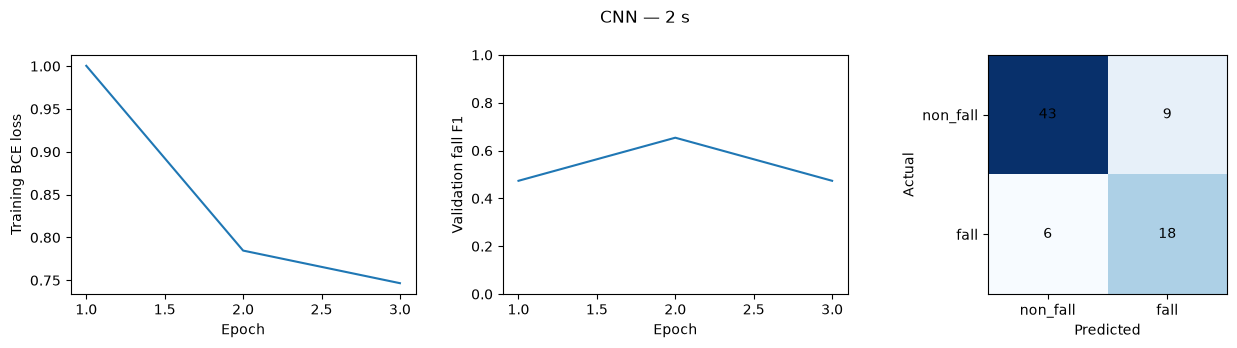

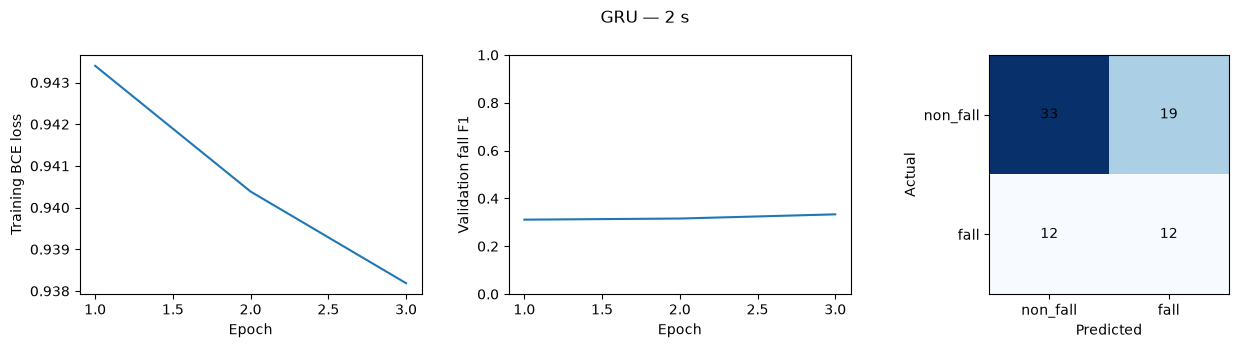

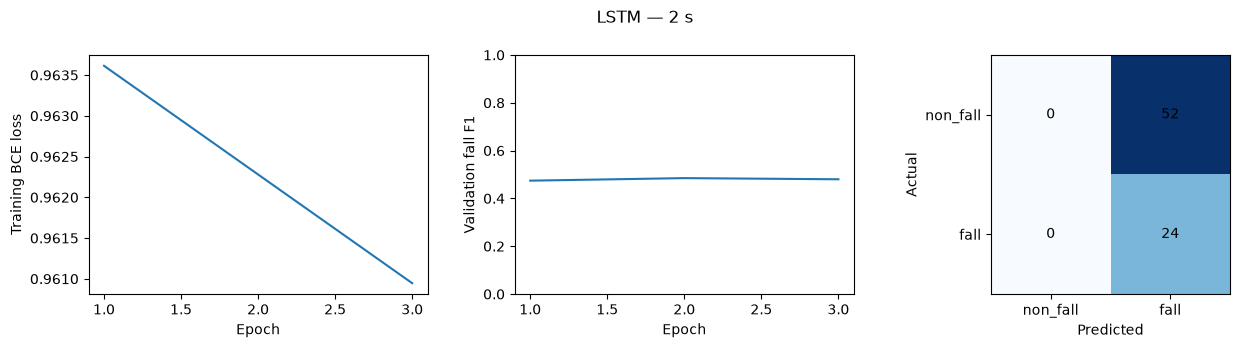

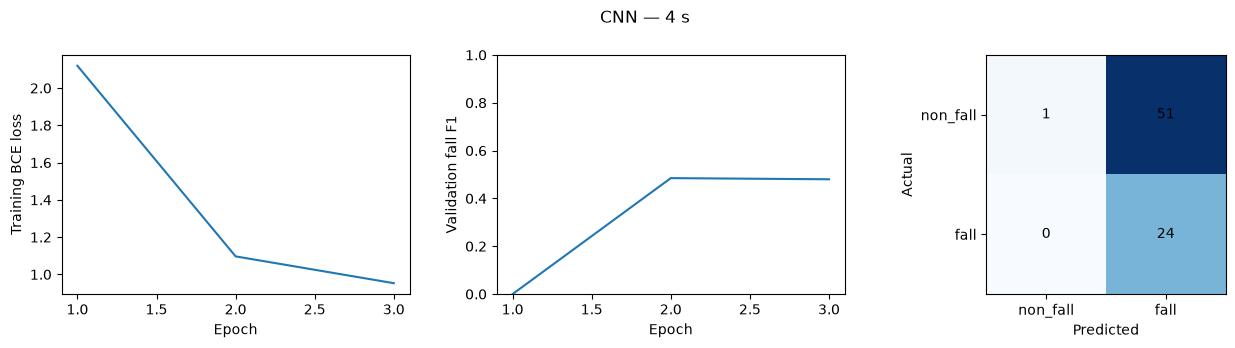

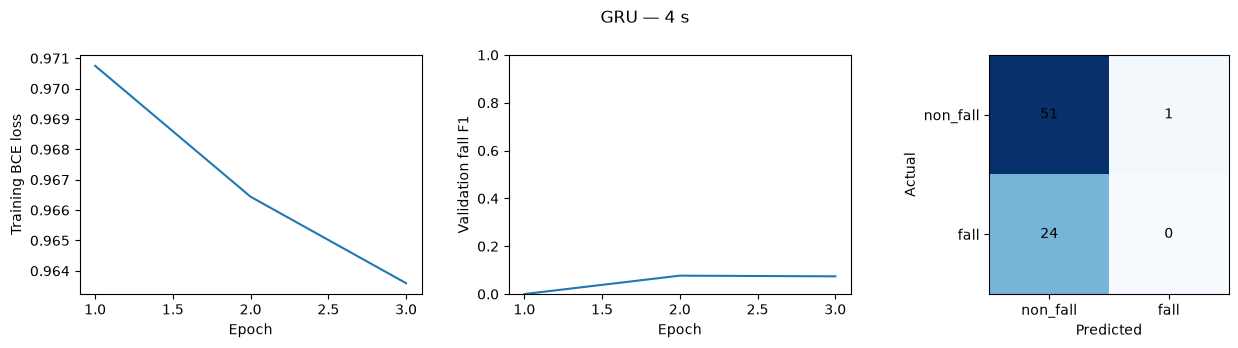

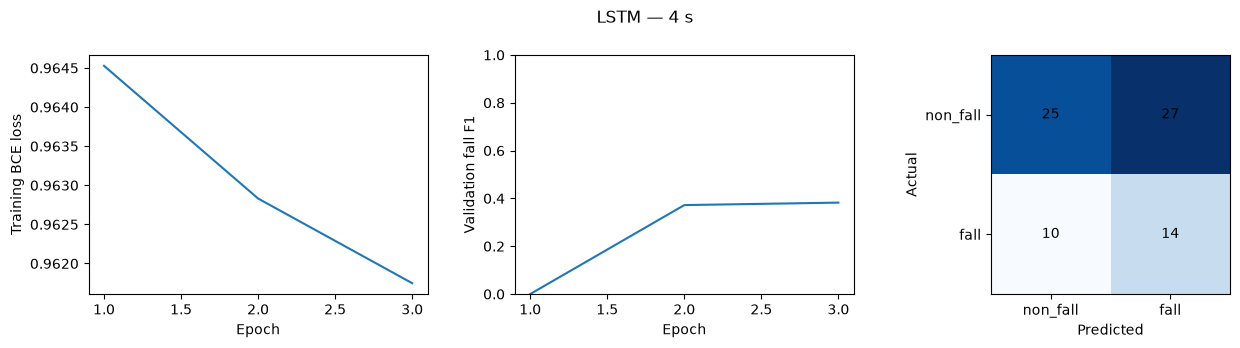

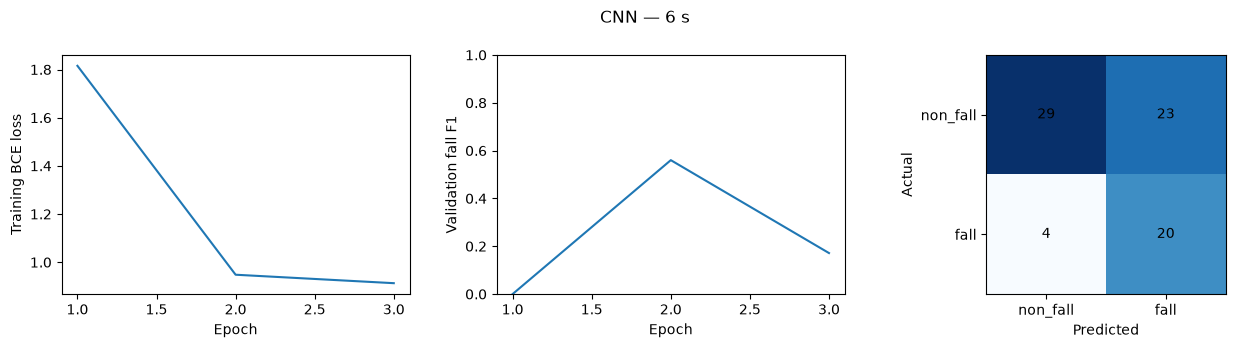

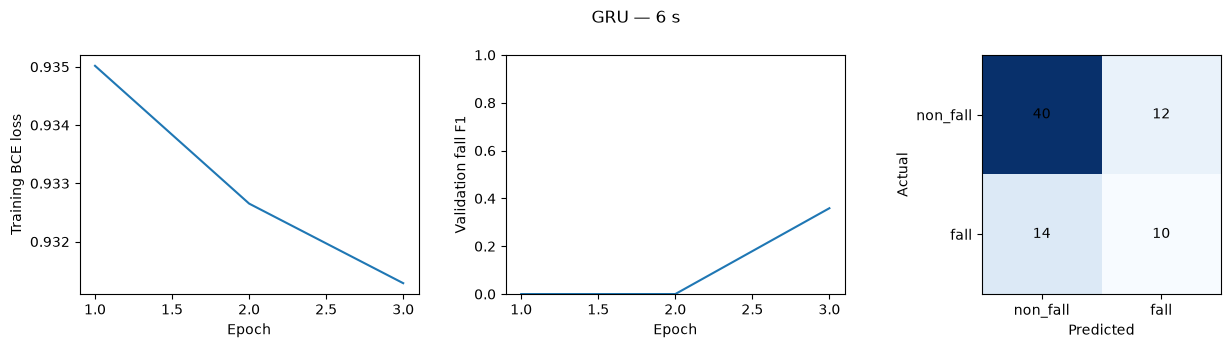

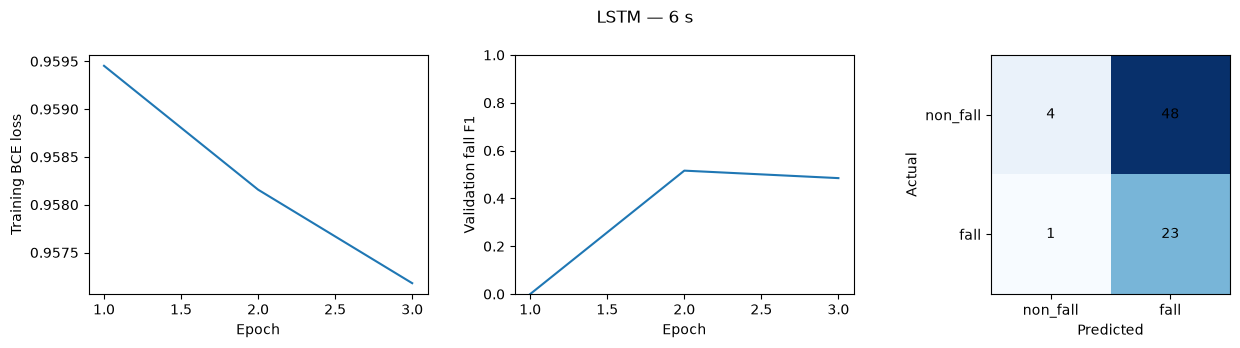

Completed 9/9 configurations. Saved to /home/khaelano/Projects/radio-fall-detection/data/processed/tinygrad_binary_v1/20261111T104436078493Z


In [15]:
results = [
    result
    for name in ("cnn_results", "lstm_results", "gru_results")
    for result in globals().get(name, [])
]
if not RUN_FULL_TRAINING:
    results = profile_results
    print("SUBSET PILOT METRICS: these are not full-dataset model-quality results.")
comparison = comparison_table(results)
comparison.write_csv(RESULT_DIR / ("comparison.csv" if RUN_FULL_TRAINING else "profile/model_metrics.csv"))
display(comparison)
for result in results:
    print(result["model"].upper(), f'{result["duration_seconds"]}s',
          "test per-class metrics:", result["test"]["per_class"])
plot_results(results, RESULT_DIR if RUN_FULL_TRAINING else RESULT_DIR / "profile")
print(f"Completed {len(results)}/9 configurations. Saved to {RESULT_DIR}")

## Reload a saved model

Reconstruct the checkpoint and saved normalization in a memory-limited worker. The worker checks the first test window against its saved prediction.

In [16]:
LOAD_MODEL = "gru"
LOAD_WINDOW_SECONDS = 4
loaded_prediction = run_worker(RESULT_DIR if RUN_FULL_TRAINING else RESULT_DIR / "profile", "predict", kind=LOAD_MODEL, duration=LOAD_WINDOW_SECONDS)
display(loaded_prediction)

=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===


{'actual': 'non_fall',
 'predicted': 'non_fall',
 'fall_probability': 0.31577637791633606,
 'checkpoint': '/home/khaelano/Projects/radio-fall-detection/data/processed/tinygrad_binary_v1/20261111T104436078493Z/profile/4s/gru'}